In [9]:
import sys
import os

# Add the project root (where the nn/ folder lives) to the import path
sys.path.insert(0, os.path.abspath('..'))

# Now you can import from nn
from nn import network2
from nn import mnist_loader

Epoch 0 training complete
Cost on training data: 0.3297166361363805
Epoch 0 training complete
Cost on training data: 1.3263575205955076
Epoch 0 training complete
Cost on training data: 0.3250714335575769
Epoch 0 training complete
Cost on training data: 1.1693787464676282
Epoch 0 training complete
Cost on training data: 0.3202771250498675
Epoch 0 training complete
Cost on training data: 1.0314748132749751
Epoch 0 training complete
Cost on training data: 0.31533308998883125
Epoch 0 training complete
Cost on training data: 0.9115884246679079
Epoch 0 training complete
Cost on training data: 0.3102394586631111
Epoch 0 training complete
Cost on training data: 0.8081763982072461
Epoch 0 training complete
Cost on training data: 0.30499720648382234
Epoch 0 training complete
Cost on training data: 0.7194247238352461
Epoch 0 training complete
Cost on training data: 0.29960824804679126
Epoch 0 training complete
Cost on training data: 0.6434432863041419
Epoch 0 training complete
Cost on training da

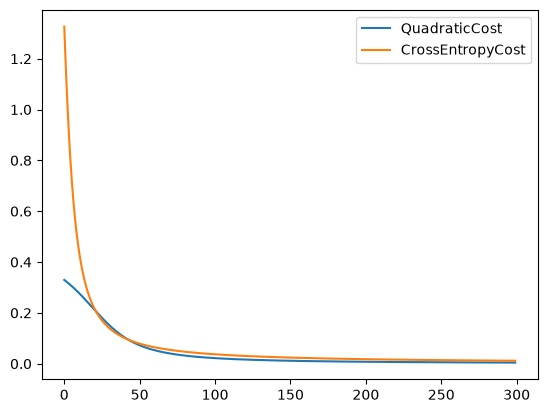

In [10]:
# PART 1 - recreate the cost graphs

import numpy as np

net1 = network2.Network([1, 1], cost=network2.QuadraticCost)
net2 = network2.Network([1, 1], cost=network2.CrossEntropyCost)

training_data = [(np.array([[1.0]]), np.array([[0.0]]))]
net1.weights= [np.array([[0.6]])]
net1.biases = [np.array([[0.9]])]

costs1 = []
costs2 = []
for _ in range(300):
    (_, _, train_cost, _) = net1.SGD(training_data, 1, 1, 0.15, 0.0, monitor_training_cost=True)
    costs1.append(train_cost[0])
    (_, _, train_cost, _) = net2.SGD(training_data, 1, 1, 0.15, 0.0, monitor_training_cost=True)
    costs2.append(train_cost[0])

import matplotlib.pyplot as plt

plt.plot(costs1, label='QuadraticCost')
plt.plot(costs2, label='CrossEntropyCost')
plt.legend()
plt.show()



In [11]:
# PART 2 - Overfitting and regularization
import matplotlib.pyplot as plt

training_data, validation_data, test_data = mnist_loader.load_data_wrapper('../nn/mnist.pkl.gz')

training_data = list(training_data)
validation_data = list(validation_data)
test_data = list(test_data)


def run_experiment(data_size, regularization):
    net = network2.Network(
        [784, 30, 10],
        cost=network2.CrossEntropyCost
    )

    net.large_weight_initializer()

    results = net.SGD(
        training_data[:data_size],
        epochs=100,
        mini_batch_size=10,
        eta=0.5,
        evaluation_data=validation_data,
        lmbda=regularization,
        monitor_training_cost=True,
        monitor_training_accuracy=True,
        monitor_evaluation_cost=True,
        monitor_evaluation_accuracy=True
    )

    return results

results_A = run_experiment(1000, 0)

results_B = run_experiment(1000, 5)

results_C = run_experiment(50000, 5)

Epoch 0 training complete
Cost on training data: 1.8789659209580778
Accuracy on training data: 654 / 1000
Cost on evaluation data: 2.189379129045471
Accuracy on evaluation data: 5576 / 10000
Epoch 1 training complete
Cost on training data: 1.3972984127272439
Accuracy on training data: 779 / 1000
Cost on evaluation data: 1.7803298066254643
Accuracy on evaluation data: 6656 / 10000
Epoch 2 training complete
Cost on training data: 1.1160522017246013
Accuracy on training data: 833 / 1000
Cost on evaluation data: 1.5991922824719509
Accuracy on evaluation data: 7037 / 10000
Epoch 3 training complete
Cost on training data: 0.9371874269968338
Accuracy on training data: 869 / 1000
Cost on evaluation data: 1.4414101703182824
Accuracy on evaluation data: 7429 / 10000
Epoch 4 training complete
Cost on training data: 0.7750691138773259
Accuracy on training data: 903 / 1000
Cost on evaluation data: 1.3521756806216152
Accuracy on evaluation data: 7667 / 10000
Epoch 5 training complete
Cost on trainin

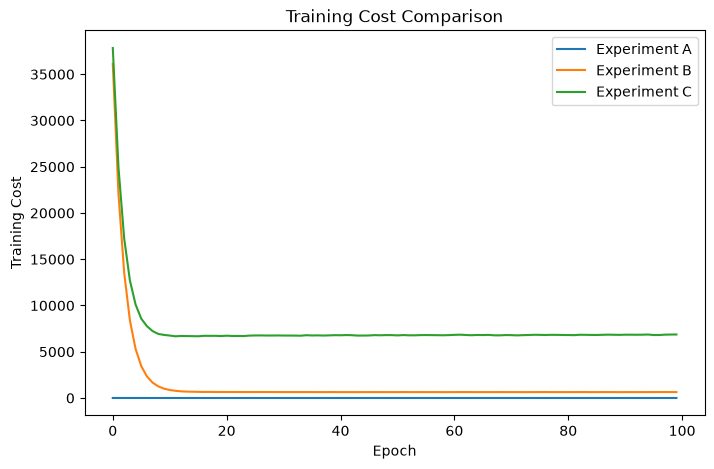

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(results_A[2], label='Experiment A')
plt.plot(results_B[2], label='Experiment B')
plt.plot(results_C[2], label='Experiment C')

plt.xlabel('Epoch')
plt.ylabel('Training Cost')
plt.title('Training Cost Comparison')
plt.legend()
plt.show()

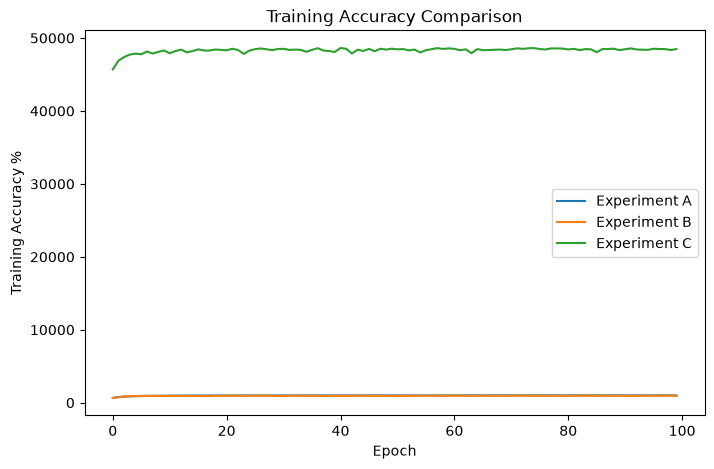

In [24]:
plt.figure(figsize=(8,5))

plt.plot(results_A[3], label='Experiment A')
plt.plot(results_B[3], label='Experiment B')
plt.plot(results_C[3], label='Experiment C')

plt.xlabel('Epoch')
plt.ylabel('Training Accuracy %')
plt.title('Training Accuracy Comparison')
plt.legend()
plt.show()

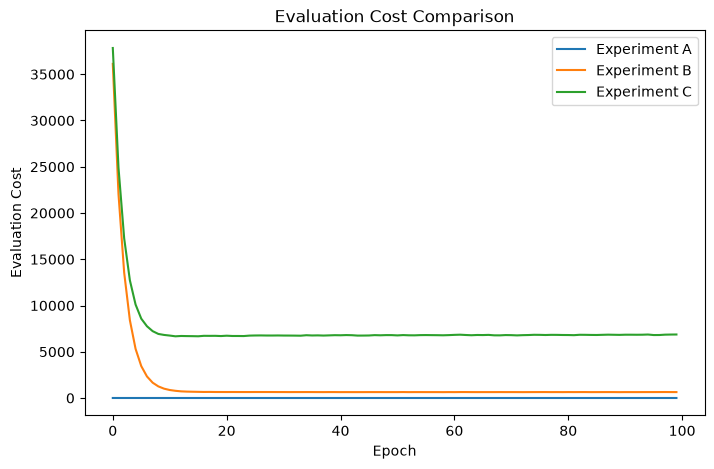

In [25]:
plt.figure(figsize=(8,5))

plt.plot(results_A[0], label='Experiment A')
plt.plot(results_B[0], label='Experiment B')
plt.plot(results_C[0], label='Experiment C')

plt.xlabel('Epoch')
plt.ylabel('Evaluation Cost')
plt.title('Evaluation Cost Comparison')
plt.legend()
plt.show()

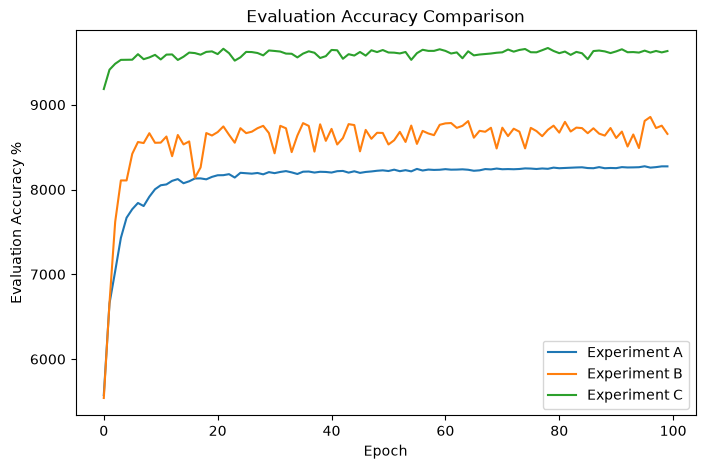

In [26]:
plt.figure(figsize=(8,5))

plt.plot(results_A[1], label='Experiment A')
plt.plot(results_B[1], label='Experiment B')
plt.plot(results_C[1], label='Experiment C')

plt.xlabel('Epoch')
plt.ylabel('Evaluation Accuracy %')
plt.title('Evaluation Accuracy Comparison')
plt.legend()
plt.show()